# Prediction of Lipophilicity Using Machine Learning

## Aim of the Project

The aim of this project is to predict the lipophilicity values of drug-like molecules using machine learning regression models. The Lipophilicity_AstraZeneca dataset is used in this project. The molecular structures are represented as SMILES strings, and the target variable is the experimentally measured lipophilicity value. Since the target variable is numerical, this project is treated as a regression problem.

## Setup

Install the dependencies from `requirements.txt` before running the notebook.


In [73]:
# Importing the libraries required for data analysis, visualization,
# molecular descriptor calculation, and machine learning models

import pandas as pd
import numpy as np

# To enable the display of plots in a Jupyter notebook
%matplotlib inline
import matplotlib.pyplot as plt

# RDKit libraries for molecular structure handling and descriptor calculation
from rdkit import Chem
from rdkit.Chem.Descriptors import MolWt, MolLogP, NumAromaticRings, NumHDonors, NumHAcceptors

# Scikit-learn libraries for splitting data, building models, optimization, and evaluation
from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# Load the Lipophilicity_AstraZeneca dataset

df = pd.read_csv("data/lipophilicity_astrazeneca.tab", sep="\t")

df.head()

In [75]:
# Check the shape of the dataset

df.shape

(4200, 3)

In [76]:
# Check column names

df.columns

Index(['Drug_ID', 'Drug', 'Y'], dtype='object')

In [77]:
print("Number of molecules:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Column names:", list(df.columns))

Number of molecules: 4200
Number of columns: 3
Column names: ['Drug_ID', 'Drug', 'Y']


## Exploratory Data Analysis


In this section, the dataset is examined before building machine learning models. The data types, missing values, summary statistics, and the distribution of the target variable are checked.

In [78]:
# Display general information about the dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Drug_ID  4200 non-null   object 
 1   Drug     4200 non-null   object 
 2   Y        4200 non-null   float64
dtypes: float64(1), object(2)
memory usage: 98.6+ KB


In [79]:
# Display summary statistics for numerical columns

df.describe()

,Y
count,4200.000000
mean,2.186336
std,1.203004
min,-1.500000
25%,1.410000
50%,2.360000
75%,3.100000
max,4.500000


In [80]:
# Check missing values in each column

df.isnull().sum()

Drug_ID    0
Drug       0
Y          0
dtype: int64

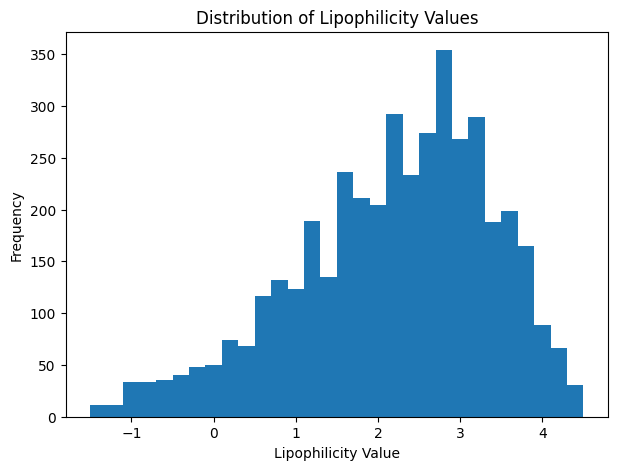

In [81]:
# Plot the distribution of the target variable 
plt.figure(figsize=(7,5))
plt.hist(df["Y"], bins=30)
plt.xlabel("Lipophilicity Value")
plt.ylabel("Frequency")
plt.title("Distribution of Lipophilicity Values")
plt.show()

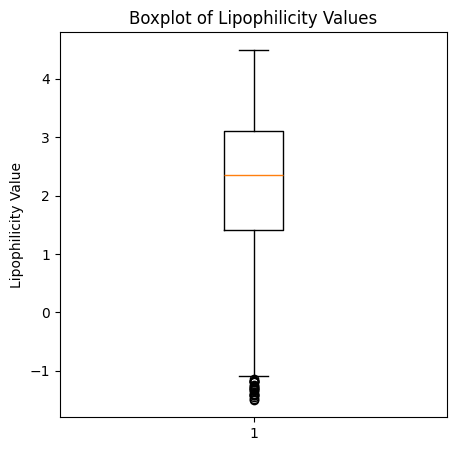

In [82]:
# Boxplot of the target variable

plt.figure(figsize=(5, 5))
plt.boxplot(df["Y"])
plt.ylabel("Lipophilicity Value")
plt.title("Boxplot of Lipophilicity Values")
plt.show()

The target variable Y represents experimental lipophilicity values. Since Y is a continuous numerical variable, the prediction task is a regression problem. The dataset does not contain missing values, so no missing value imputation was required at this stage.

## Molecular Descriptor Calculation

The original dataset contains molecular structures as SMILES strings in the Drug column. Since traditional machine learning models cannot directly use SMILES strings, molecular descriptors were calculated using RDKit. The selected descriptors are similar to those used in the regression example notebook: molecular weight, LogP, number of aromatic rings, hydrogen bond donors, and hydrogen bond acceptors.

In [120]:
from rdkit import Chem
from rdkit.Chem.Descriptors import MolWt, MolLogP, NumAromaticRings, NumHDonors, NumHAcceptors

print("RDKit imported successfully.")

RDKit imported successfully.


In [121]:
# Function to calculate molecular descriptors from SMILES strings

def calculate_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)
    
    if mol is None:
        return [np.nan, np.nan, np.nan, np.nan, np.nan]
    
    MW = MolWt(mol)
    LogP = MolLogP(mol)
    NumAromatic = NumAromaticRings(mol)
    HBD = NumHDonors(mol)
    HBA = NumHAcceptors(mol)
    
    return [MW, LogP, NumAromatic, HBD, HBA]

In [122]:
# Calculate descriptors and add them to the dataframe

desc_cols = ['MW', 'LogP', 'NumAromatic', 'HBD', 'HBA']

df[desc_cols] = df['Drug'].apply(calculate_descriptors).apply(pd.Series)

df.head()

,Drug_ID,Drug,Y,MW,LogP,NumAromatic,HBD,HBA
0,CHEMBL596271,Cn1c(CN2CCN(c3ccc(Cl)cc3)CC2)nc2ccccc21,3.54,340.858,3.5489,3.0,0.0,4.0
1,CHEMBL1951080,COc1cc(OC)c(S(=O)(=O)N2c3ccccc3CCC2C)cc1NC(=O)...,-1.18,494.591,2.9901,2.0,2.0,7.0
2,CHEMBL1771,COC(=O)[C@H](c1ccccc1Cl)N1CCc2sccc2C1,3.69,321.829,3.6739,2.0,0.0,4.0
3,CHEMBL234951,O=C(NC1Cc2ccccc2N(C[C@@H](O)CO)C1=O)c1cc2cc(Cl...,3.37,419.890,1.9237,3.0,4.0,5.0
4,CHEMBL565079,Cc1cccc(C[C@H](NC(=O)c2cc(C(C)(C)C)nn2C)C(=O)N...,3.10,381.480,2.0069,2.0,2.0,5.0


In [87]:
# Check missing values in calculated descriptors

df[desc_cols].isnull().sum()

MW             0
LogP           0
NumAromatic    0
HBD            0
HBA            0
dtype: int64

In [88]:
# Summary statistics of molecular descriptors

df[desc_cols].describe()

,MW,LogP,NumAromatic,HBD,HBA
count,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000
mean,383.141330,3.280305,2.622381,1.620000,5.137857
std,107.005433,1.322797,0.972973,1.162189,2.158695
min,113.160000,-5.621800,0.000000,0.000000,0.000000
25%,306.812750,2.432380,2.000000,1.000000,4.000000
50%,388.395500,3.277700,3.000000,1.000000,5.000000
75%,456.889500,4.115325,3.000000,2.000000,7.000000
max,1620.693000,10.342520,6.000000,22.000000,24.000000


In [89]:
# Correlation between descriptors and the target variable

correlation_data = df[desc_cols + ["Y"]].corr()

correlation_data["Y"].sort_values(ascending=False)

Y              1.000000
LogP           0.415450
NumAromatic    0.297561
MW             0.158856
HBA            0.041302
HBD           -0.195873
Name: Y, dtype: float64

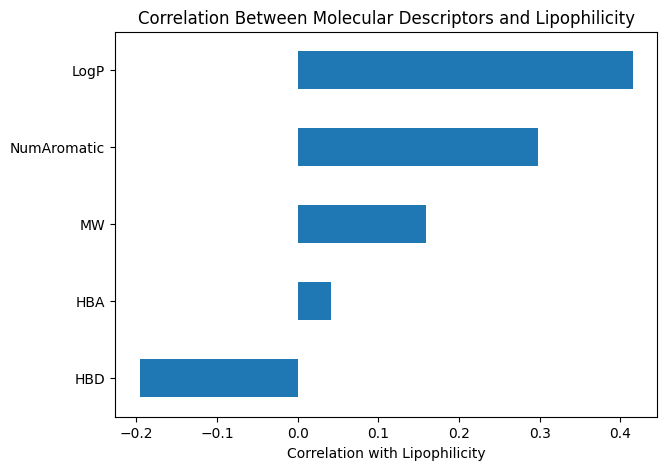

In [90]:
# Plot correlation of descriptors with lipophilicity

plt.figure(figsize=(7, 5))
correlation_data["Y"].drop("Y").sort_values().plot(kind="barh")
plt.xlabel("Correlation with Lipophilicity")
plt.title("Correlation Between Molecular Descriptors and Lipophilicity")
plt.show()

In [91]:
desc_cols = ['MW', 'LogP', 'NumAromatic', 'HBD', 'HBA']

## Train-Test Split

The dataset was split into training and test sets. The training set was used to train the regression models, while the test set was used to evaluate model performance on unseen data. The molecular descriptors were used as input features, and the Y column was used as the target variable.

In [92]:
# Split the dataset into training and test sets

train, test = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

print("Training set shape:", train.shape)
print("Test set shape:", test.shape)

Training set shape: (3360, 8)
Test set shape: (840, 8)


In [93]:
# Define input features and target variable

train_X = train[desc_cols]
train_y = train["Y"]

test_X = test[desc_cols]
test_y = test["Y"]

print("train_X shape:", train_X.shape)
print("train_y shape:", train_y.shape)
print("test_X shape:", test_X.shape)
print("test_y shape:", test_y.shape)

train_X shape: (3360, 5)
train_y shape: (3360,)
test_X shape: (840, 5)
test_y shape: (840,)


In [94]:
train_X.head()

,MW,LogP,NumAromatic,HBD,HBA
2417,437.544,3.5819,2.0,3.0,5.0
3827,211.308,3.1032,2.0,1.0,1.0
239,448.545,2.5162,2.0,0.0,8.0
3633,522.642,3.6157,6.0,2.0,11.0
1543,134.142,0.5401,2.0,2.0,3.0


In [95]:
train_y.head()

2417    2.48
3827    1.70
239     3.27
3633    3.09
1543    1.78
Name: Y, dtype: float64

## Regression Models

In this section, different regression models were trained using the molecular descriptors as input features. The models were evaluated using MAE, RMSE, and R² score. Since the target variable is continuous, regression metrics were used instead of classification metrics.

In [96]:
# Define regression models

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "Support Vector Regression": SVR()
}

In [97]:
# Train and evaluate each regression model

results = []

for model_name, model in models.items():
    model.fit(train_X, train_y)
    predictions = model.predict(test_X)
    
    mae = mean_absolute_error(test_y, predictions)
    mse = mean_squared_error(test_y, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(test_y, predictions)
    
    results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

results_df

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,0.844346,1.158897,1.076521,0.215623
1,Ridge Regression,0.859811,1.184536,1.088364,0.198270
2,Decision Tree,0.937637,1.645529,1.282782,-0.113745
3,Random Forest,0.727084,0.951237,0.975314,0.356174
4,Gradient Boosting,0.783171,1.028510,1.014155,0.303873
5,Support Vector Regression,0.961186,1.486166,1.219084,-0.005883


In [98]:
# Sort models based on RMSE

results_df = results_df.sort_values(by="RMSE")

results_df

,Model,MAE,MSE,RMSE,R2
3,Random Forest,0.727084,0.951237,0.975314,0.356174
4,Gradient Boosting,0.783171,1.028510,1.014155,0.303873
0,Linear Regression,0.844346,1.158897,1.076521,0.215623
1,Ridge Regression,0.859811,1.184536,1.088364,0.198270
5,Support Vector Regression,0.961186,1.486166,1.219084,-0.005883
2,Decision Tree,0.937637,1.645529,1.282782,-0.113745


In [99]:
# Select the best model based on the lowest RMSE

best_model_name = results_df.iloc[0]["Model"]
best_model_rmse = results_df.iloc[0]["RMSE"]
best_model_r2 = results_df.iloc[0]["R2"]

print("Best model based on RMSE:", best_model_name)
print("RMSE:", best_model_rmse)
print("R²:", best_model_r2)

Best model based on RMSE: Random Forest
RMSE: 0.9753137837591405
R²: 0.35617367012415346


**Evaluation note:** The original exploratory analysis compares models on the test set and then uses that same test set to choose a model for tuning. This means the selected model’s test score may be optimistic. For a rigorous estimate, select and tune models using cross-validation on the training set, then evaluate the final choice once on an untouched test set.

The regression models were compared using MAE, MSE, RMSE, and R² score. RMSE was used as the main criterion for model selection because it represents the prediction error in the same unit as the target variable and penalizes larger errors more strongly.

## Model Performance Visualization

The performances of the regression models were visualized using bar plots. RMSE and R² score were used to compare the models. Lower RMSE and higher R² indicate better model performance.

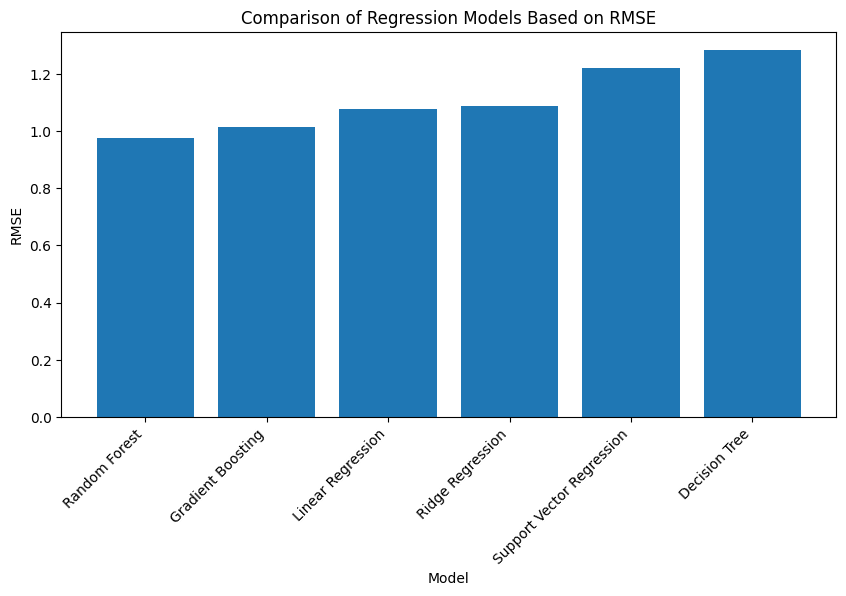

In [100]:
# Visualize RMSE values for regression models

plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("Comparison of Regression Models Based on RMSE")
plt.xticks(rotation=45, ha="right")
plt.show()

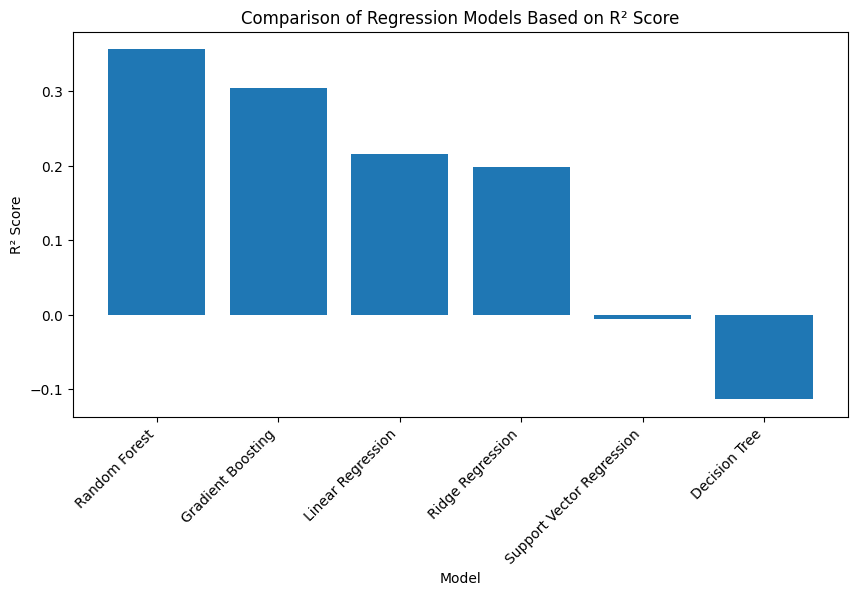

In [101]:
# Visualize R² scores for regression models

plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["R2"])
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("Comparison of Regression Models Based on R² Score")
plt.xticks(rotation=45, ha="right")
plt.show()

The models were compared using RMSE and R² score. RMSE was used as the main criterion for selecting the best model because it represents the prediction error in the same unit as the target variable. The model with the lowest RMSE value was selected for hyperparameter optimization.

## Hyperparameter Optimization

After comparing the regression models, the best-performing model was selected based on the lowest RMSE value. GridSearchCV was then used to optimize some hyperparameters of the selected model.

In [102]:
# Check the best model based on RMSE

best_model_name = results_df.iloc[0]["Model"]

print("Best model based on RMSE:", best_model_name)

Best model based on RMSE: Random Forest


In [103]:
# Hyperparameter optimization for Random Forest Regressor

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10]
}

grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(train_X, train_y)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation RMSE:", -grid_search.best_score_)

Python(96402) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(96403) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(96404) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(96405) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Best parameters: {'max_depth': 20, 'min_samples_split': 10, 'n_estimators': 300}
Best cross-validation RMSE: 0.9727682871474673


In [104]:
# Evaluate the optimized Random Forest model on the test set

optimized_model = grid_search.best_estimator_

optimized_predictions = optimized_model.predict(test_X)

optimized_mae = mean_absolute_error(test_y, optimized_predictions)
optimized_mse = mean_squared_error(test_y, optimized_predictions)
optimized_rmse = np.sqrt(optimized_mse)
optimized_r2 = r2_score(test_y, optimized_predictions)

print("Optimized MAE:", optimized_mae)
print("Optimized MSE:", optimized_mse)
print("Optimized RMSE:", optimized_rmse)
print("Optimized R²:", optimized_r2)

Optimized MAE: 0.732968044217161
Optimized MSE: 0.9410059851500586
Optimized RMSE: 0.9700546299822802
Optimized R²: 0.36309831872341836


In [105]:
# Store optimized model performance in a dataframe

optimized_results_df = pd.DataFrame({
    "Model": ["Optimized Random Forest"],
    "MAE": [optimized_mae],
    "MSE": [optimized_mse],
    "RMSE": [optimized_rmse],
    "R2": [optimized_r2]
})

optimized_results_df


,Model,MAE,MSE,RMSE,R2
0,Optimized Random Forest,0.732968,0.941006,0.970055,0.363098


In [106]:
# Compare initial model performances with the optimized model

final_results_df = pd.concat(
    [results_df, optimized_results_df],
    ignore_index=True
)

final_results_df = final_results_df.sort_values(by="RMSE")

final_results_df

,Model,MAE,MSE,RMSE,R2
6,Optimized Random Forest,0.732968,0.941006,0.970055,0.363098
0,Random Forest,0.727084,0.951237,0.975314,0.356174
1,Gradient Boosting,0.783171,1.028510,1.014155,0.303873
2,Linear Regression,0.844346,1.158897,1.076521,0.215623
3,Ridge Regression,0.859811,1.184536,1.088364,0.198270
4,Support Vector Regression,0.961186,1.486166,1.219084,-0.005883
5,Decision Tree,0.937637,1.645529,1.282782,-0.113745


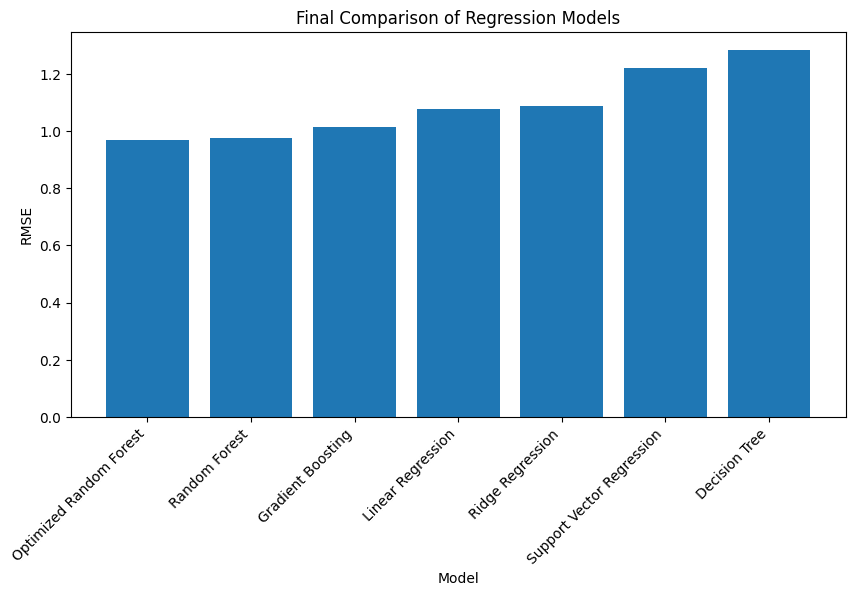

In [107]:
# Visualize final model comparison based on RMSE

plt.figure(figsize=(10, 5))
plt.bar(final_results_df["Model"], final_results_df["RMSE"])
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("Final Comparison of Regression Models")
plt.xticks(rotation=45, ha="right")
plt.show()

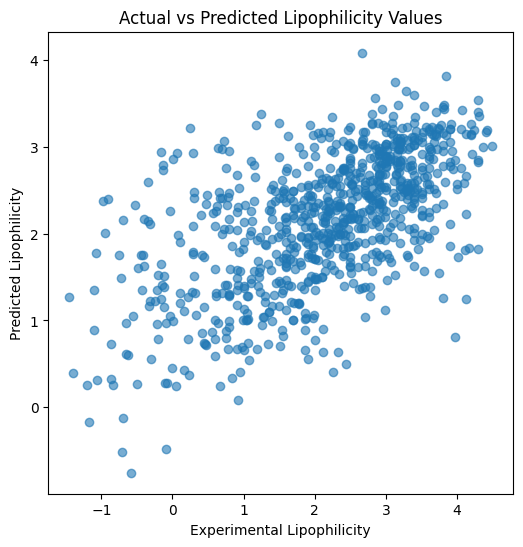

In [108]:
# Plot actual vs predicted lipophilicity values for the optimized Random Forest model

plt.figure(figsize=(6, 6))
plt.scatter(test_y, optimized_predictions, alpha=0.6)
plt.xlabel("Experimental Lipophilicity")
plt.ylabel("Predicted Lipophilicity")
plt.title("Actual vs Predicted Lipophilicity Values")
plt.show()

The optimized Random Forest model was evaluated on the test set using MAE, MSE, RMSE, and R² score. The actual versus predicted plot was used to visually compare the predicted lipophilicity values with the experimental values.

## Additional Molecular Representation: Morgan Fingerprints

In addition to the simple RDKit molecular descriptors, Morgan fingerprints were calculated from SMILES strings. Morgan fingerprints encode molecular substructures as binary vectors and provide a more detailed representation of molecular structure.

This additional approach was included to compare whether a structural fingerprint-based representation improves the prediction of lipophilicity compared to using only simple molecular descriptors.

In [109]:
# Import libraries required for Morgan fingerprint calculation

from rdkit.Chem import AllChem
from rdkit import DataStructs

In [110]:
# Function to convert SMILES strings into Morgan fingerprints

def smiles_to_morgan_fingerprint(smiles, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smiles)
    
    if mol is None:
        return np.zeros(n_bits)
    
    fingerprint = AllChem.GetMorganFingerprintAsBitVect(
        mol,
        radius,
        nBits=n_bits
    )
    
    array = np.zeros((n_bits,), dtype=int)
    DataStructs.ConvertToNumpyArray(fingerprint, array)
    
    return array

In [111]:
# Calculate Morgan fingerprints for all molecules

X_fp = np.array([
    smiles_to_morgan_fingerprint(smiles) for smiles in df["Drug"]
])

y_fp = df["Y"].values

print("Morgan fingerprint feature matrix shape:", X_fp.shape)
print("Target vector shape:", y_fp.shape)

Morgan fingerprint feature matrix shape: (4200, 2048)
Target vector shape: (4200,)


In [112]:
# Split Morgan fingerprint data into training and test sets

fp_train_X, fp_test_X, fp_train_y, fp_test_y = train_test_split(
    X_fp,
    y_fp,
    test_size=0.2,
    random_state=42
)

print("Fingerprint training set shape:", fp_train_X.shape)
print("Fingerprint test set shape:", fp_test_X.shape)

Fingerprint training set shape: (3360, 2048)
Fingerprint test set shape: (840, 2048)


In [113]:
# Define regression models for Morgan fingerprint features

fingerprint_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "Support Vector Regression": SVR()
}

In [114]:
# Train and evaluate regression models using Morgan fingerprints

fingerprint_results = []

for model_name, model in fingerprint_models.items():
    model.fit(fp_train_X, fp_train_y)
    predictions = model.predict(fp_test_X)
    
    mae = mean_absolute_error(fp_test_y, predictions)
    mse = mean_squared_error(fp_test_y, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(fp_test_y, predictions)
    
    fingerprint_results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

fingerprint_results_df = pd.DataFrame(fingerprint_results)
fingerprint_results_df = fingerprint_results_df.sort_values(by="RMSE")

fingerprint_results_df

,Model,MAE,MSE,RMSE,R2
5,Support Vector Regression,0.581411,0.599768,0.774447,0.594059
3,Random Forest,0.615473,0.679782,0.824489,0.539903
1,Ridge Regression,0.685668,0.846843,0.920241,0.426831
4,Gradient Boosting,0.737611,0.861742,0.928301,0.416746
2,Decision Tree,0.813322,1.169794,1.081570,0.208248
0,Linear Regression,0.918834,1.627744,1.275831,-0.101707


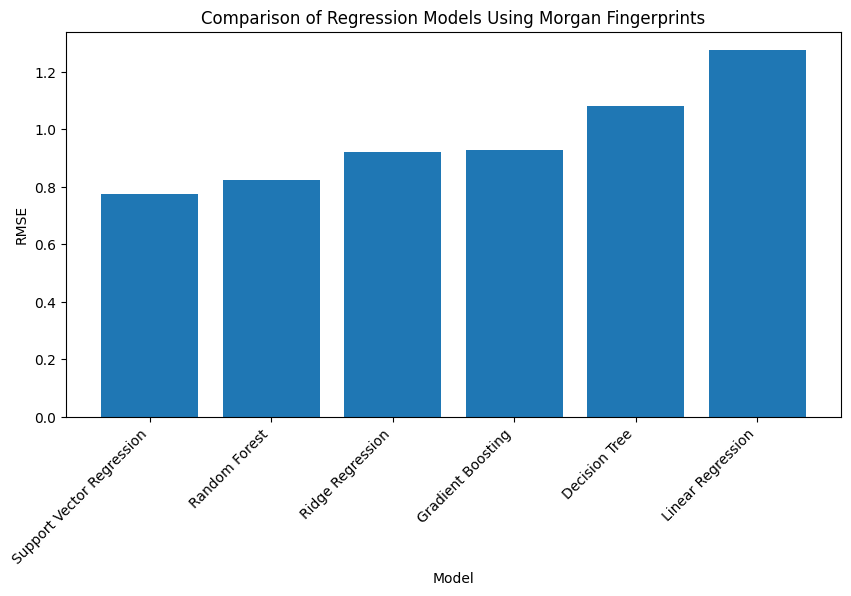

In [115]:
# Visualize RMSE values for Morgan fingerprint models

plt.figure(figsize=(10, 5))
plt.bar(fingerprint_results_df["Model"], fingerprint_results_df["RMSE"])
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("Comparison of Regression Models Using Morgan Fingerprints")
plt.xticks(rotation=45, ha="right")
plt.show()

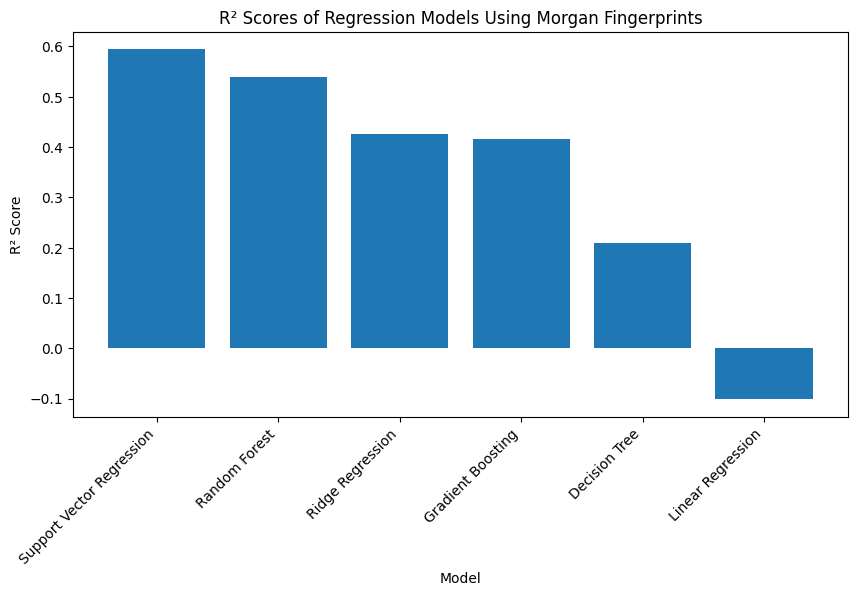

In [116]:
# Visualize R² scores for Morgan fingerprint models

plt.figure(figsize=(10, 5))
plt.bar(fingerprint_results_df["Model"], fingerprint_results_df["R2"])
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("R² Scores of Regression Models Using Morgan Fingerprints")
plt.xticks(rotation=45, ha="right")
plt.show()

## Comparison of Descriptor-Based and Fingerprint-Based Models

The performances of the models trained with simple RDKit molecular descriptors were compared with the performances of the models trained with Morgan fingerprints. This comparison was performed to evaluate whether a more detailed molecular representation improves lipophilicity prediction.

In [117]:
# Add feature type labels to compare descriptor-based and fingerprint-based models

descriptor_results_df = results_df.copy()
descriptor_results_df["Feature_Type"] = "RDKit Descriptors"

fingerprint_comparison_df = fingerprint_results_df.copy()
fingerprint_comparison_df["Feature_Type"] = "Morgan Fingerprints"

combined_results_df = pd.concat(
    [descriptor_results_df, fingerprint_comparison_df],
    ignore_index=True
)

combined_results_df = combined_results_df.sort_values(by="RMSE")

combined_results_df

,Model,MAE,MSE,RMSE,R2,Feature_Type
6,Support Vector Regression,0.581411,0.599768,0.774447,0.594059,Morgan Fingerprints
7,Random Forest,0.615473,0.679782,0.824489,0.539903,Morgan Fingerprints
8,Ridge Regression,0.685668,0.846843,0.920241,0.426831,Morgan Fingerprints
9,Gradient Boosting,0.737611,0.861742,0.928301,0.416746,Morgan Fingerprints
0,Random Forest,0.727084,0.951237,0.975314,0.356174,RDKit Descriptors
1,Gradient Boosting,0.783171,1.028510,1.014155,0.303873,RDKit Descriptors
2,Linear Regression,0.844346,1.158897,1.076521,0.215623,RDKit Descriptors
10,Decision Tree,0.813322,1.169794,1.081570,0.208248,Morgan Fingerprints
3,Ridge Regression,0.859811,1.184536,1.088364,0.198270,RDKit Descriptors
4,Support Vector Regression,0.961186,1.486166,1.219084,-0.005883,RDKit Descriptors


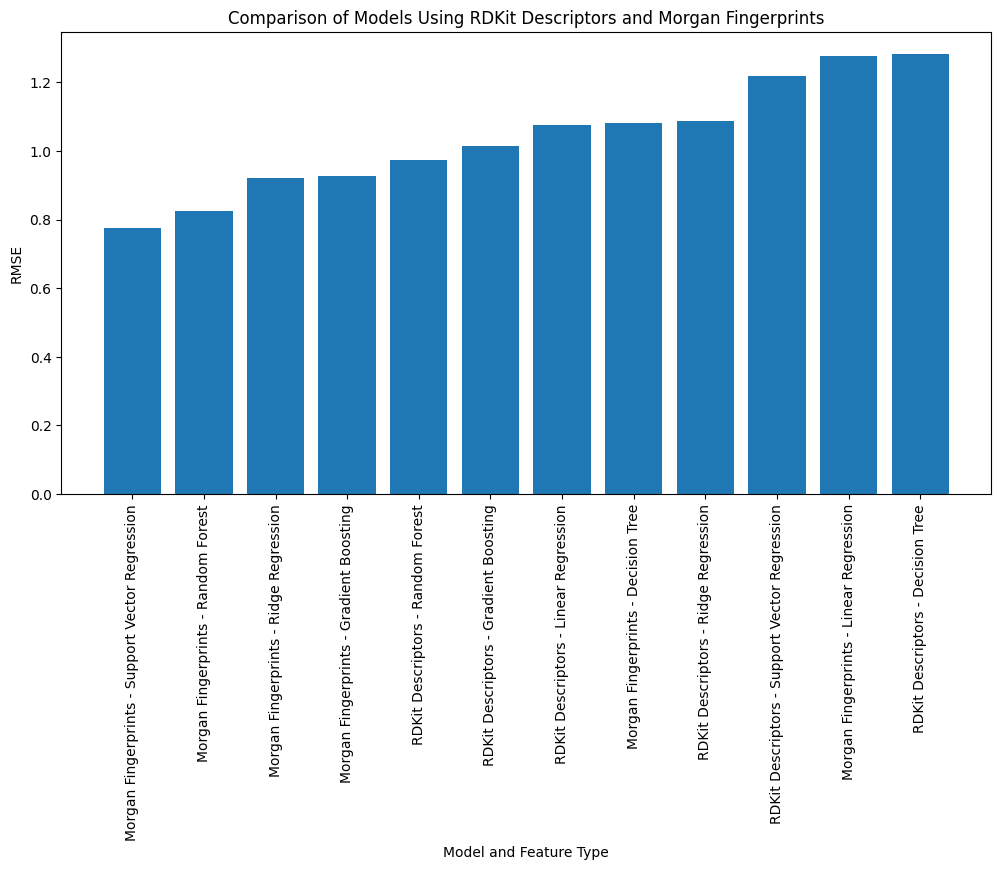

In [118]:
# Visualize RMSE comparison between descriptor-based and fingerprint-based models

combined_results_df["Model_Feature"] = (
    combined_results_df["Feature_Type"] + " - " + combined_results_df["Model"]
)

plt.figure(figsize=(12, 6))
plt.bar(combined_results_df["Model_Feature"], combined_results_df["RMSE"])
plt.xlabel("Model and Feature Type")
plt.ylabel("RMSE")
plt.title("Comparison of Models Using RDKit Descriptors and Morgan Fingerprints")
plt.xticks(rotation=90)
plt.show()

In [119]:
# Select the best overall model based on the lowest RMSE

best_overall_model = combined_results_df.iloc[0]

print("Best overall model:")
print("Feature type:", best_overall_model["Feature_Type"])
print("Model:", best_overall_model["Model"])
print("RMSE:", best_overall_model["RMSE"])
print("R²:", best_overall_model["R2"])

Best overall model:
Feature type: Morgan Fingerprints
Model: Support Vector Regression
RMSE: 0.7744467624607645
R²: 0.5940587854824441


Morgan fingerprint-based models showed better predictive performance than models using simple RDKit descriptors. This suggests that molecular substructures contain important information for predicting lipophilicity.

## Conclusion

In this project, machine learning regression models were developed to predict lipophilicity values using the Lipophilicity_AstraZeneca dataset. Since the target variable Y is a continuous numerical value, the problem was treated as a regression task.

Molecular descriptors were calculated from SMILES strings using RDKit. These descriptors were used as input features for different regression models. Six regression algorithms were trained and compared: Linear Regression, Ridge Regression, Decision Tree Regressor, Random Forest Regressor, Gradient Boosting Regressor, and Support Vector Regression.

The models were evaluated using MAE, MSE, RMSE, and R² score. Among the descriptor-based models, Random Forest Regressor achieved the best performance based on RMSE and was selected for hyperparameter optimization. GridSearchCV was used to optimize selected hyperparameters of the Random Forest model.

As an additional comparison, Morgan fingerprints were also calculated to represent molecular substructures more directly. The fingerprint-based models showed better performance than the simple descriptor-based models, which suggests that molecular representation has an important effect on lipophilicity prediction.

Overall, the results show that machine learning regression models can be used to predict molecular lipophilicity. The project also demonstrates that using more detailed molecular representations, such as Morgan fingerprints, can improve predictive performance compared to using only simple molecular descriptors.

These results are exploratory because the test set was used during model selection.